In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("/Users/anupamverma/Internship Projects/Real State/Data/india_housing_prices.csv")

print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
print(df.info())

Rows: 250000, Columns: 23
<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   ID                              250000 non-null  int64  
 1   State                           250000 non-null  str    
 2   City                            250000 non-null  str    
 3   Locality                        250000 non-null  str    
 4   Property_Type                   250000 non-null  str    
 5   BHK                             250000 non-null  int64  
 6   Size_in_SqFt                    250000 non-null  int64  
 7   Price_in_Lakhs                  250000 non-null  float64
 8   Price_per_SqFt                  250000 non-null  float64
 9   Year_Built                      250000 non-null  int64  
 10  Furnished_Status                250000 non-null  str    
 11  Floor_No                        250000 non-null  int64  
 12  T

In [2]:
# Convert categorical columns
cat_cols = [
    'State',
    'City',
    'Property_Type',
    'Furnished_Status',
    'Public_Transport_Accessibility',
    'Parking_Space',
    'Security',
    'Facing',
    'Owner_Type',
    'Availability_Status',
]
for col in cat_cols:
  df[col] = df[col].astype('category')

# Downcast integers to save memory
df['BHK'] = df['BHK'].astype('int8')
df['Floor_No'] = df['Floor_No'].astype('int16')
df['Total_Floors'] = df['Total_Floors'].astype('int16')
df['Age_of_Property'] = df['Age_of_Property'].astype('int16')
df['Nearby_Schools'] = df['Nearby_Schools'].astype('int8')
df['Nearby_Hospitals'] = df['Nearby_Hospitals'].astype('int8')
df['Year_Built'] = df['Year_Built'].astype('int16')
df['Size_in_SqFt'] = df['Size_in_SqFt'].astype('int32')

# Check updated info and memory usage
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype   
---  ------                          --------------   -----   
 0   ID                              250000 non-null  int64   
 1   State                           250000 non-null  category
 2   City                            250000 non-null  category
 3   Locality                        250000 non-null  str     
 4   Property_Type                   250000 non-null  category
 5   BHK                             250000 non-null  int8    
 6   Size_in_SqFt                    250000 non-null  int32   
 7   Price_in_Lakhs                  250000 non-null  float64 
 8   Price_per_SqFt                  250000 non-null  float64 
 9   Year_Built                      250000 non-null  int16   
 10  Furnished_Status                250000 non-null  category
 11  Floor_No                        250000 non-null  int16   
 12  Total_Floors 

### Data Preprocessing

In [3]:
print("\n Missing Values Summary")
missing_vals = df.isnull().sum()
print(missing_vals[missing_vals > 0] if missing_vals.sum() > 0 else "No missing values found!")

print("\n Duplicate Rows ")
print(f"Total duplicate rows: {df.duplicated().sum()}")


 Missing Values Summary
No missing values found!

 Duplicate Rows 
Total duplicate rows: 0


In [4]:
current_year = 2025

# Calculate / Recalculate Age_of_Property
if 'Year_Built' in df.columns:
    df['Age_of_Property'] = current_year - df['Year_Built']
    df['Age_of_Property'] = df['Age_of_Property'].apply(lambda x: max(0, x))

# Recompute Price_per_SqFt (Price in Lakhs -> convert to Rupees)
# 1 Lakh = 100,000 INR
df['Price_per_SqFt'] = (df['Price_in_Lakhs'] * 100000) / df['Size_in_SqFt']
df['Price_per_SqFt'] = df['Price_per_SqFt'].round(2)

# Create Infrastructure / Connectivity Score
# Combining Schools, Hospitals, and Transport rating into an index (1 to 5 scale)
# Map text transport ratings to numbers
transport_mapping = {'Low': 1, 'Medium': 3, 'High': 5}  # Adjust based on your actual categories
df['Public_Transport_Accessibility_Num'] = df[
    'Public_Transport_Accessibility'
].map(transport_mapping)

infra_cols = ['Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility_Num']
existing_infra = [c for c in infra_cols if c in df.columns]

if len(existing_infra) > 0:
    df['Infrastructure_Score'] = df[existing_infra].mean(axis=1).round(2)
else:
    df['Infrastructure_Score'] = 3.0  # default score


In [5]:
#Step 4: Create Target Variables


# A-> REGRESSION TARGET: Future_Price_5Y 
# Formula: Future_Price = Current_Price * (1 + annual_rate)^5
# Annual growth rate dynamic calculation:
# Base growth rate = 7% (0.07)
# High infrastructure / Good location bonus = +2% growth
base_rate = 0.07
infra_bonus = np.where(df['Infrastructure_Score'] >= 3.5, 0.02, 0.0)
annual_rate = base_rate + infra_bonus

df['Future_Price_5Y'] = df['Price_in_Lakhs'] * ((1 + annual_rate) ** 5)
df['Future_Price_5Y'] = df['Future_Price_5Y'].round(2)


# B-> CLASSIFICATION TARGET: Good_Investment 
# Multi-Factor Business Rules based on Document Specifications:
# 1. Price per SqFt is below or equal to the Locality/City median price per sqft.
# 2. Infrastructure score >= Median Infrastructure score.
# 3. Property age <= 20 years.

# Locality / City Median Price per SqFt
if 'Locality' in df.columns:
    df['Locality_Median_Price_SqFt'] = df.groupby('Locality')['Price_per_SqFt'].transform('median')
else:
    df['Locality_Median_Price_SqFt'] = df.groupby('City')['Price_per_SqFt'].transform('median')

# Multi-factor Condition Checks
cond_price = df['Price_per_SqFt'] <= df['Locality_Median_Price_SqFt']
cond_infra = df['Infrastructure_Score'] >= df['Infrastructure_Score'].median()
cond_age = df['Age_of_Property'] <= 20

# Require at least 2 out of 3 positive conditions to classify as "Good Investment" (1)
score = cond_price.astype(int) + cond_infra.astype(int) + cond_age.astype(int)
df['Good_Investment'] = (score >= 2).astype(int)

# Drop temporary calculation columns
df = df.drop(columns=['Locality_Median_Price_SqFt'])

print(f"Target Regression Range (Future_Price_5Y): ₹{df['Future_Price_5Y'].min():.2f} L to ₹{df['Future_Price_5Y'].max():.2f} L")
print("Target Classification Value Counts (Good_Investment):")
print(df['Good_Investment'].value_counts(normalize=True).round(3).rename({1: 'Good (1)', 0: 'Not Good (0)'}))

Target Regression Range (Future_Price_5Y): ₹14.03 L to ₹769.31 L
Target Classification Value Counts (Good_Investment):
Good_Investment
Good (1)        0.552
Not Good (0)    0.448
Name: proportion, dtype: float64


In [6]:
import os
output_dir = os.path.join("..","Data", "processed")
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, "cleaned_housing_prices.csv")

df.to_csv(output_path, index=False)
print(f"\n✅ Preprocessed dataset saved to: {output_path}")


✅ Preprocessed dataset saved to: ../Data/processed/cleaned_housing_prices.csv


In [7]:
df

,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status,Public_Transport_Accessibility_Num,Infrastructure_Score,Future_Price_5Y,Good_Investment
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,10332.49,1990,...,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move,5,6.00,753.56,0
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,8270.73,2008,...,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction,1,3.33,274.23,1
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,5046.40,1997,...,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move,1,6.00,282.78,1
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,10955.49,1991,...,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move,5,5.67,462.03,0
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,3792.25,2002,...,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move,1,4.67,281.41,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,249996,Gujarat,Ahmedabad,Locality_187,Independent House,5,1995,274.75,13771.93,1995,...,No,No,"Playground, Garden, Gym, Clubhouse, Pool",East,Broker,Under_Construction,1,5.00,422.74,0
249996,249997,Tamil Nadu,Chennai,Locality_348,Apartment,1,2293,13.40,584.39,2013,...,No,No,Playground,South,Broker,Ready_to_Move,1,6.33,20.62,1
249997,249998,Telangana,Warangal,Locality_225,Villa,4,2910,236.94,8142.27,2003,...,Yes,Yes,Playground,South,Builder,Under_Construction,5,6.33,364.56,1
249998,249999,Odisha,Cuttack,Locality_138,Villa,1,1149,141.66,12328.98,2007,...,Yes,Yes,"Playground, Gym, Pool",South,Owner,Ready_to_Move,1,3.67,217.96,0


### Exploaratory Data Analysis

***Section 1: Price & Size Analysis***

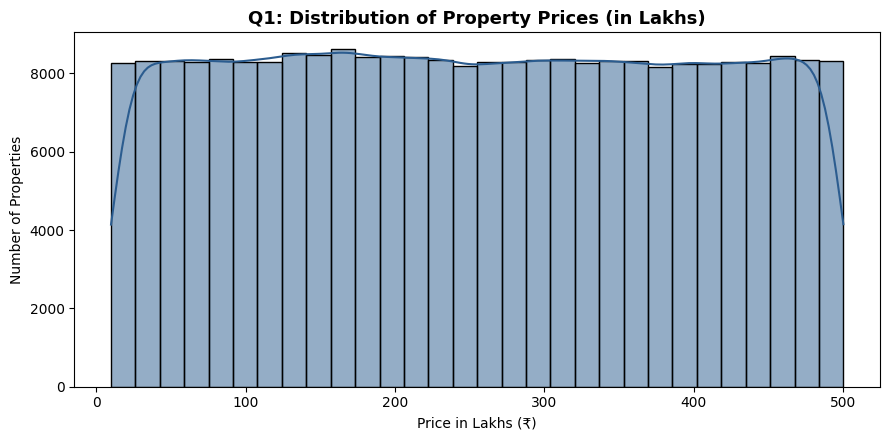

📌 EXPLANATION:
• Visualizes how property total prices are spread across the dataset.
• The curve is right-skewed, showing most properties sit in affordable/mid-budget ranges with few luxury listings.
• Helps investors understand the standard market price range before setting budget limits.



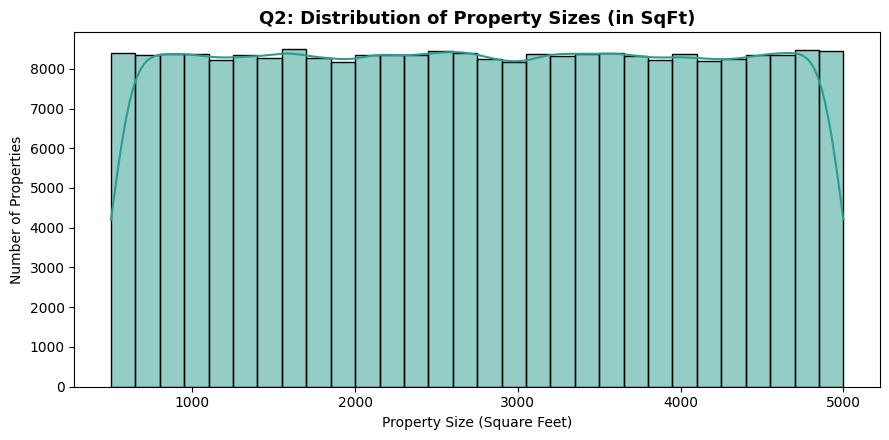

📌 EXPLANATION:
• Shows the distribution of property floor areas measured in square feet.
• Most listings cluster between 800 to 2,500 sq ft, representing standard residential homes.
• Identifies common unit dimensions to help categorize properties into small, medium, and large layouts.



/var/folders/fs/kf96xh5s589d5vwpbjc0_4p40000gn/T/ipykernel_28125/3266915896.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Property_Type', y='Price_per_SqFt', palette='Set2')


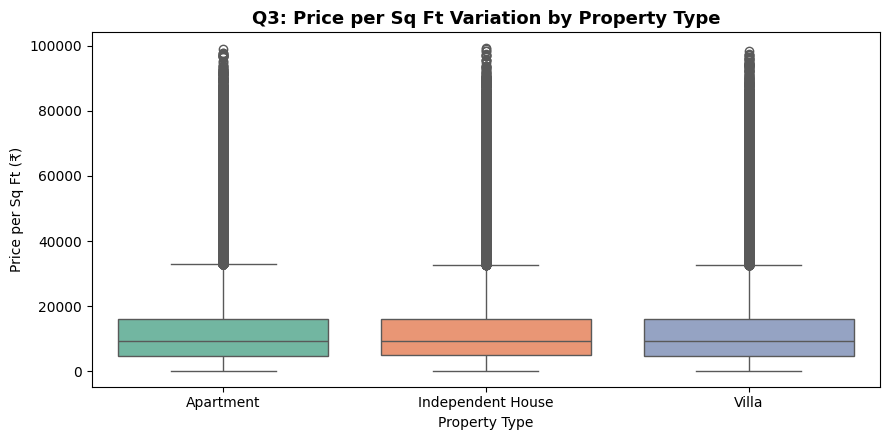

📌 EXPLANATION:
• Compares the rate per square foot across Villas, Apartments, and Houses.
• Villas and independent houses generally command higher per-sq-ft rates than apartments due to land ownership.
• Proves that property type is a critical factor when determining fair market value per square foot.



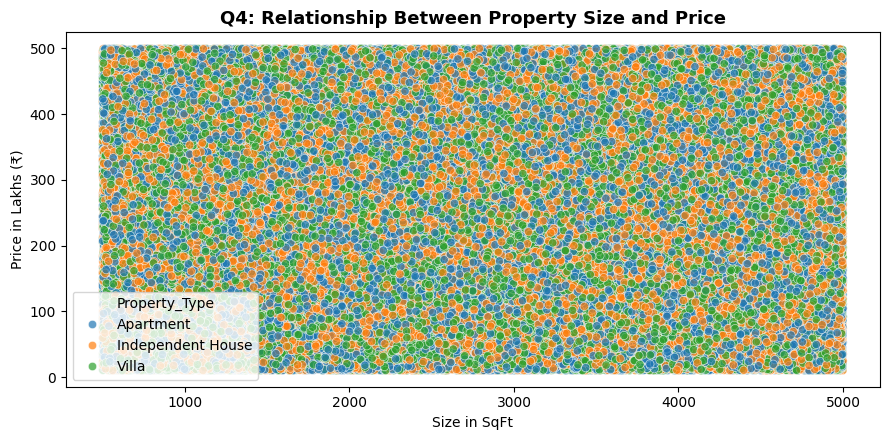

📌 EXPLANATION:
• Illustrates the direct mathematical relationship between total square footage and total price.
• Displays a strong positive trend, confirming larger properties consistently command higher final prices.
• Validates property size as one of the strongest predictors for regression price modeling.



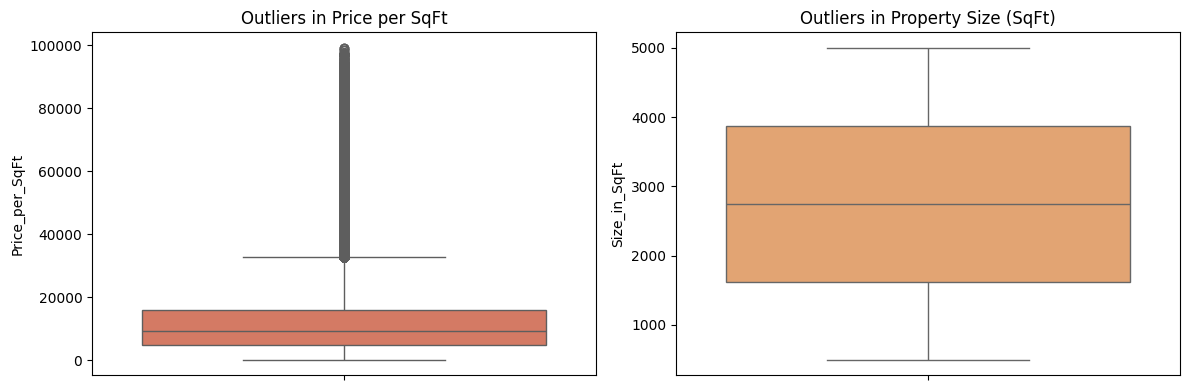

📌 EXPLANATION:
• Highlights extreme values lying outside 1.5 times the Interquartile Range (IQR).
• Dots above the top line represent ultra-luxury listings or anomalous data points.
• Helps clean extreme outliers before model training so skewness doesn't distort predictions.



In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Q1: Distribution of Property Prices

plt.figure(figsize=(9, 4.5))
sns.histplot(df['Price_in_Lakhs'], kde=True, color='#2b5c8f', bins=30)
plt.title("Q1: Distribution of Property Prices (in Lakhs)", fontsize=13, fontweight='bold')
plt.xlabel("Price in Lakhs (₹)")
plt.ylabel("Number of Properties")
plt.tight_layout()
plt.show()

print("""📌 EXPLANATION:
• Visualizes how property total prices are spread across the dataset.
• The curve is right-skewed, showing most properties sit in affordable/mid-budget ranges with few luxury listings.
• Helps investors understand the standard market price range before setting budget limits.
""")


# Q2: Distribution of Property Sizes

plt.figure(figsize=(9, 4.5))
sns.histplot(df['Size_in_SqFt'], kde=True, color='#2a9d8f', bins=30)
plt.title("Q2: Distribution of Property Sizes (in SqFt)", fontsize=13, fontweight='bold')
plt.xlabel("Property Size (Square Feet)")
plt.ylabel("Number of Properties")
plt.tight_layout()
plt.show()

print("""📌 EXPLANATION:
• Shows the distribution of property floor areas measured in square feet.
• Most listings cluster between 800 to 2,500 sq ft, representing standard residential homes.
• Identifies common unit dimensions to help categorize properties into small, medium, and large layouts.
""")


# Q3: Price per Sq Ft by Property Type

plt.figure(figsize=(9, 4.5))
sns.boxplot(data=df, x='Property_Type', y='Price_per_SqFt', palette='Set2')
plt.title("Q3: Price per Sq Ft Variation by Property Type", fontsize=13, fontweight='bold')
plt.xlabel("Property Type")
plt.ylabel("Price per Sq Ft (₹)")
plt.tight_layout()
plt.show()

print("""📌 EXPLANATION:
• Compares the rate per square foot across Villas, Apartments, and Houses.
• Villas and independent houses generally command higher per-sq-ft rates than apartments due to land ownership.
• Proves that property type is a critical factor when determining fair market value per square foot.
""")


# Q4: Property Size vs Total Price

plt.figure(figsize=(9, 4.5))
sns.scatterplot(data=df, x='Size_in_SqFt', y='Price_in_Lakhs', hue='Property_Type', alpha=0.7, palette='tab10')
plt.title("Q4: Relationship Between Property Size and Price", fontsize=13, fontweight='bold')
plt.xlabel("Size in SqFt")
plt.ylabel("Price in Lakhs (₹)")
plt.tight_layout()
plt.show()

print("""📌 EXPLANATION:
• Illustrates the direct mathematical relationship between total square footage and total price.
• Displays a strong positive trend, confirming larger properties consistently command higher final prices.
• Validates property size as one of the strongest predictors for regression price modeling.
""")


# Q5: Outlier Detection in Price and Size

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(y=df['Price_per_SqFt'], ax=axes[0], color='#e76f51')
axes[0].set_title("Outliers in Price per SqFt")

sns.boxplot(y=df['Size_in_SqFt'], ax=axes[1], color='#f4a261')
axes[1].set_title("Outliers in Property Size (SqFt)")
plt.tight_layout()
plt.show()

print("""📌 EXPLANATION:
• Highlights extreme values lying outside 1.5 times the Interquartile Range (IQR).
• Dots above the top line represent ultra-luxury listings or anomalous data points.
• Helps clean extreme outliers before model training so skewness doesn't distort predictions.
""")

***Section 2: Location-Based Analysis***

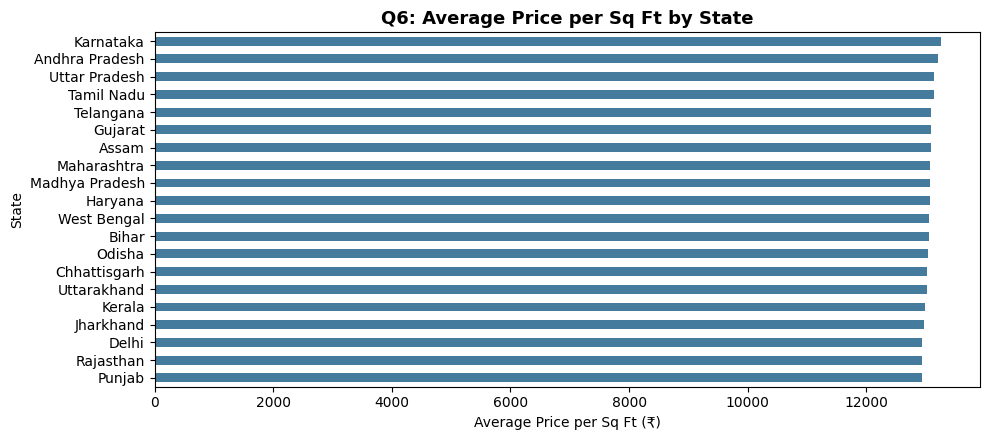

📌 EXPLANATION:
• Ranks states based on their average price per square foot.
• States with major metro cities display much higher baseline pricing due to demand and land scarcity.
• Demonstrates how geographical state location sets the overall pricing baseline for real estate.



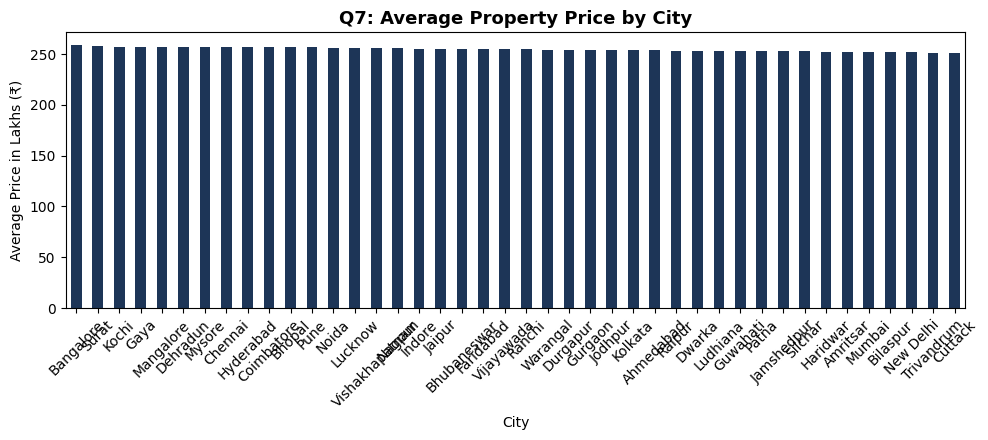

📌 EXPLANATION:
• Compares average property budgets needed across different city markets.
• Tier-1 cities require significantly higher capital investment compared to developing Tier-2 cities.
• Serves as a financial entry guide for real estate investors planning regional expansion.



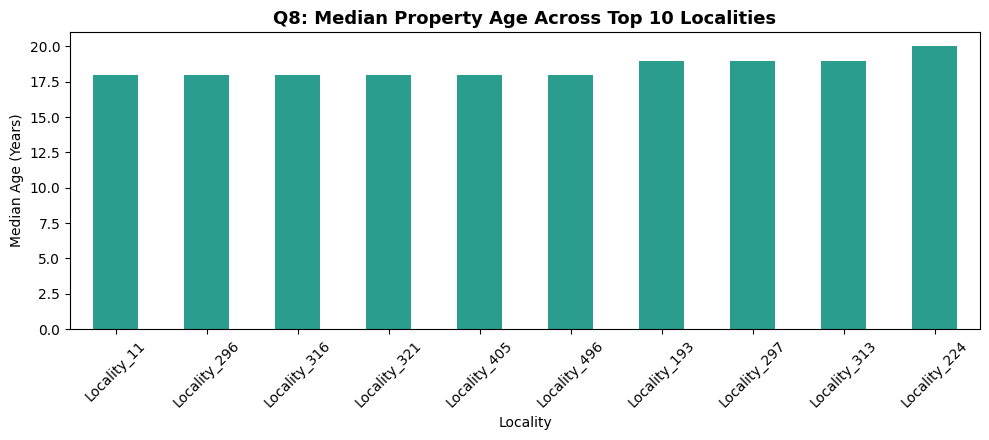

📌 EXPLANATION:
• Shows the average age of buildings across major micro-market neighborhoods.
• Older localities represent established prime areas, while newer localities indicate fresh housing developments.
• Helps buyers judge structural age, maintenance requirements, and potential renovation needs.



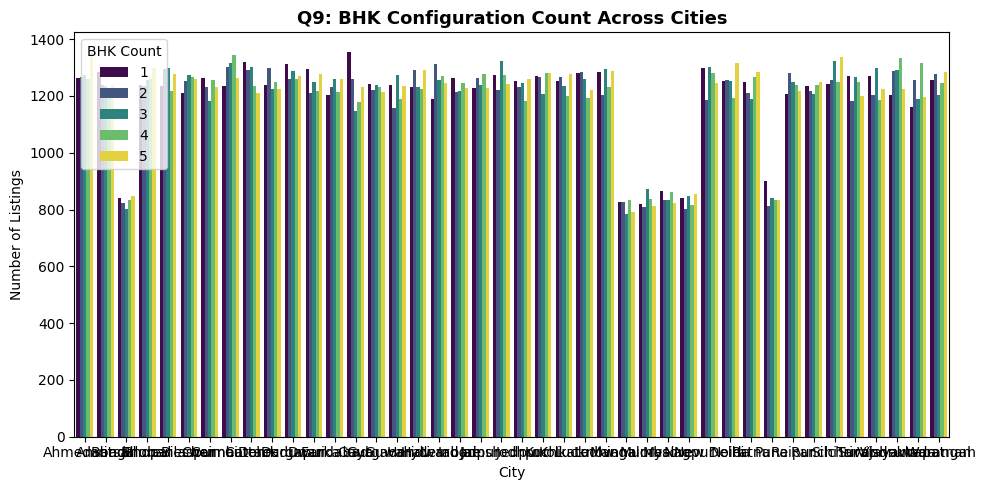

📌 EXPLANATION:
• Displays room configuration options (1 BHK to 4+ BHK) available in each city.
• Metros have a higher ratio of compact 1 & 2 BHK units, while suburbs lean toward spacious 3+ BHKs.
• Reveals localized consumer preferences and demographic housing trends.



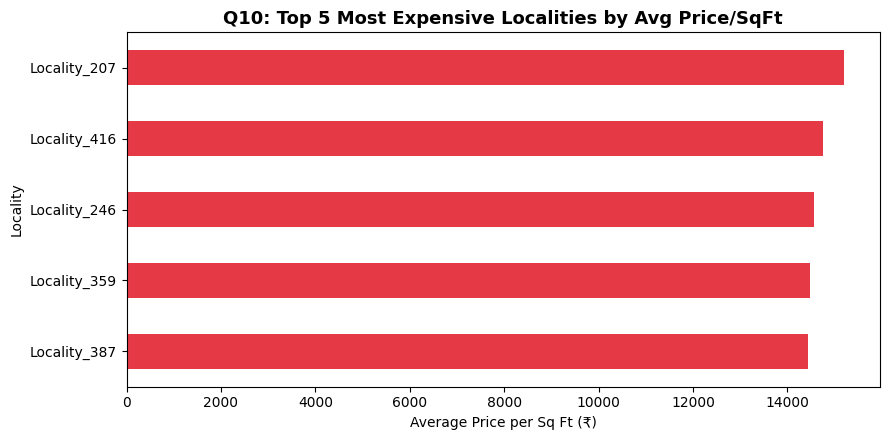

📌 EXPLANATION:
• Identifies the 5 highest-priced micro-markets based on square-foot rates.
• Highlights high-end luxury zones driven by prime access, security, and elite amenities.
• Helps benchmark premium real estate against average city market rates.



In [9]:

# Q6: Average Price per Sq Ft by State

plt.figure(figsize=(10, 4.5))
df.groupby('State')['Price_per_SqFt'].mean().sort_values().plot(kind='barh', color='#457b9d')
plt.title("Q6: Average Price per Sq Ft by State", fontsize=13, fontweight='bold')
plt.xlabel("Average Price per Sq Ft (₹)")
plt.ylabel("State")
plt.tight_layout()
plt.show()

print("""📌 EXPLANATION:
• Ranks states based on their average price per square foot.
• States with major metro cities display much higher baseline pricing due to demand and land scarcity.
• Demonstrates how geographical state location sets the overall pricing baseline for real estate.
""")


# Q7: Average Property Price by City

plt.figure(figsize=(10, 4.5))
df.groupby('City')['Price_in_Lakhs'].mean().sort_values(ascending=False).plot(kind='bar', color='#1d3557')
plt.title("Q7: Average Property Price by City", fontsize=13, fontweight='bold')
plt.xlabel("City")
plt.ylabel("Average Price in Lakhs (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("""📌 EXPLANATION:
• Compares average property budgets needed across different city markets.
• Tier-1 cities require significantly higher capital investment compared to developing Tier-2 cities.
• Serves as a financial entry guide for real estate investors planning regional expansion.
""")


# Q8: Median Property Age by Locality

top_localities = df['Locality'].value_counts().head(10).index
plt.figure(figsize=(10, 4.5))
df[df['Locality'].isin(top_localities)].groupby('Locality')['Age_of_Property'].median().sort_values().plot(kind='bar', color='#2a9d8f')
plt.title("Q8: Median Property Age Across Top 10 Localities", fontsize=13, fontweight='bold')
plt.xlabel("Locality")
plt.ylabel("Median Age (Years)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("""📌 EXPLANATION:
• Shows the average age of buildings across major micro-market neighborhoods.
• Older localities represent established prime areas, while newer localities indicate fresh housing developments.
• Helps buyers judge structural age, maintenance requirements, and potential renovation needs.
""")


# Q9: BHK Distribution Across Cities

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='City', hue='BHK', palette='viridis')
plt.title("Q9: BHK Configuration Count Across Cities", fontsize=13, fontweight='bold')
plt.xlabel("City")
plt.ylabel("Number of Listings")
plt.legend(title="BHK Count")
plt.tight_layout()
plt.show()

print("""📌 EXPLANATION:
• Displays room configuration options (1 BHK to 4+ BHK) available in each city.
• Metros have a higher ratio of compact 1 & 2 BHK units, while suburbs lean toward spacious 3+ BHKs.
• Reveals localized consumer preferences and demographic housing trends.
""")


# Q10: Top 5 Most Expensive Localities

plt.figure(figsize=(9, 4.5))
top5_exp = df.groupby('Locality')['Price_per_SqFt'].mean().nlargest(5)
top5_exp.sort_values().plot(kind='barh', color='#e63946')
plt.title("Q10: Top 5 Most Expensive Localities by Avg Price/SqFt", fontsize=13, fontweight='bold')
plt.xlabel("Average Price per Sq Ft (₹)")
plt.ylabel("Locality")
plt.tight_layout()
plt.show()

print("""📌 EXPLANATION:
• Identifies the 5 highest-priced micro-markets based on square-foot rates.
• Highlights high-end luxury zones driven by prime access, security, and elite amenities.
• Helps benchmark premium real estate against average city market rates.
""")

***Section 3 — Feature Relationship & Correlation***

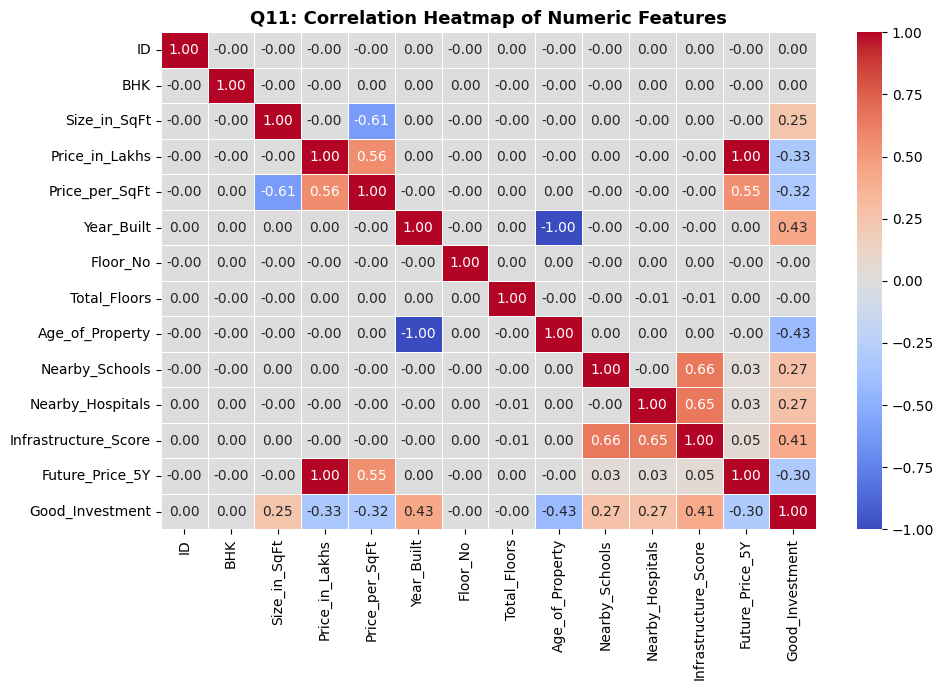

📌 EXPLANATION:
• Displays statistical correlation scores between all numeric features in a color grid.
• Values close to +1.0 indicate strong positive links (e.g., Size and Price heavily correlate).
• Helps detect multi-collinearity issues to build cleaner machine learning models.



/var/folders/fs/kf96xh5s589d5vwpbjc0_4p40000gn/T/ipykernel_28125/1971945893.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Nearby_Schools', y='Price_per_SqFt', palette='Blues')


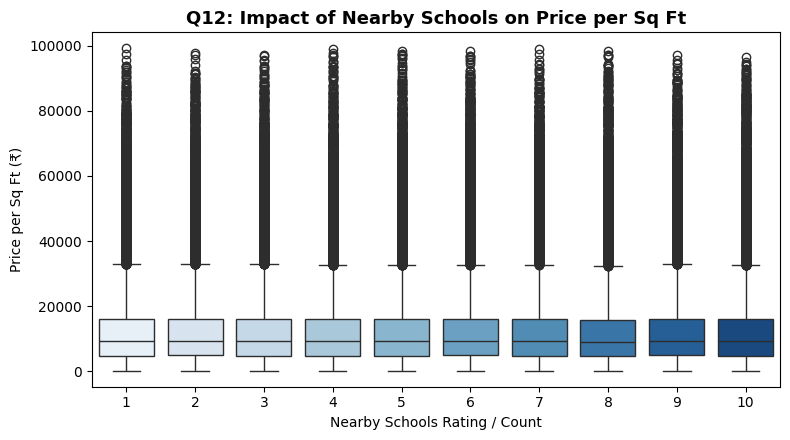

📌 EXPLANATION:
• Analyzes how access to nearby educational institutions influences unit prices.
• Locations with better school accessibility show higher average price per square foot.
• Proves that educational infrastructure directly increases residential property value.



/var/folders/fs/kf96xh5s589d5vwpbjc0_4p40000gn/T/ipykernel_28125/1971945893.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Nearby_Hospitals', y='Price_per_SqFt', palette='Greens')


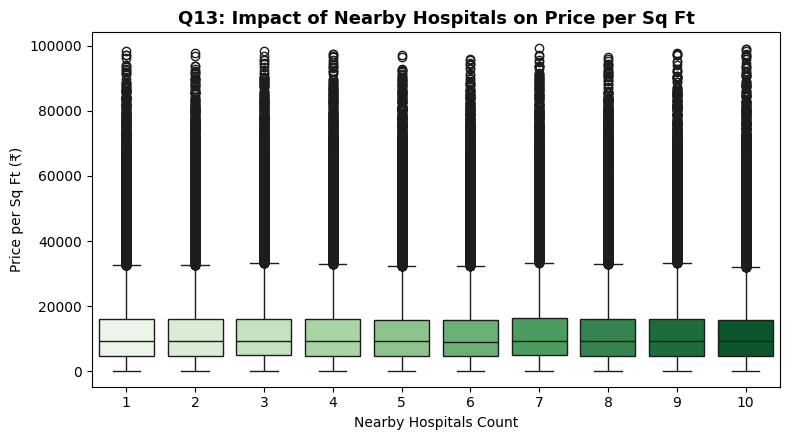

📌 EXPLANATION:
• Evaluates the connection between healthcare facility accessibility and property price.
• Areas with nearby hospitals maintain higher overall market valuation and steady resale demand.
• Confirms medical infrastructure is a key factor in assessing property long-term value.



/var/folders/fs/kf96xh5s589d5vwpbjc0_4p40000gn/T/ipykernel_28125/1971945893.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Furnished_Status', y='Price_in_Lakhs', palette='magma')


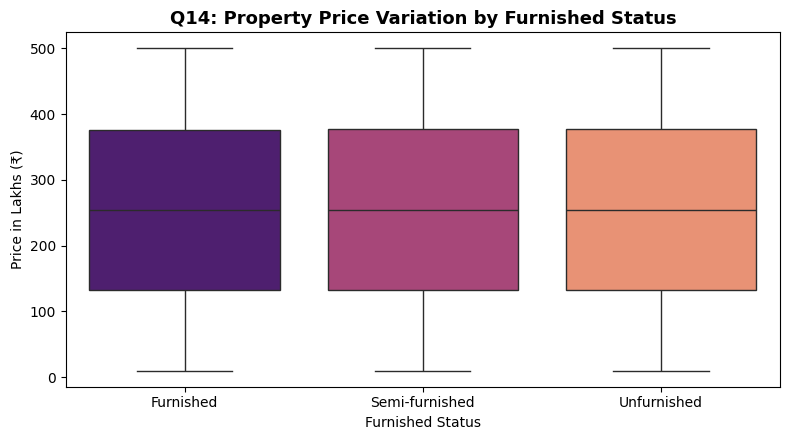

📌 EXPLANATION:
• Compares total prices across Fully Furnished, Semi-Furnished, and Unfurnished listings.
• Fully furnished properties carry a clear price premium due to ready move-in convenience.
• Helps buyers calculate immediate furnishing costs versus upfront purchase price.



/var/folders/fs/kf96xh5s589d5vwpbjc0_4p40000gn/T/ipykernel_28125/1971945893.py:73: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='Facing', y='Price_per_SqFt', palette='rocket', ci=None)
/var/folders/fs/kf96xh5s589d5vwpbjc0_4p40000gn/T/ipykernel_28125/1971945893.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Facing', y='Price_per_SqFt', palette='rocket', ci=None)


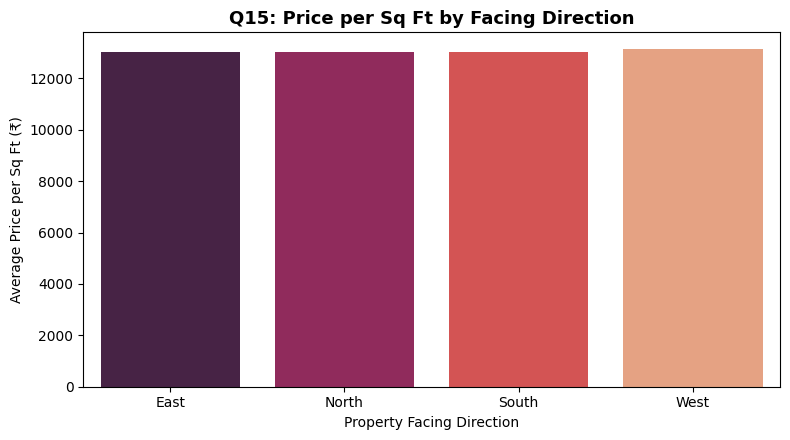

📌 EXPLANATION:
• Inspects whether directional orientation (East, North, South, West) affects unit price.
• North and East facing units often command slightly higher rates due to sunlight preference & Vastu demand.
• Shows consumer behavioral preferences within local housing markets.



In [10]:

# Q11: Numerical Features Correlation Heatmap

plt.figure(figsize=(10, 7))
numeric_cols = df.select_dtypes(include=[np.number]).columns
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title("Q11: Correlation Heatmap of Numeric Features", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("""📌 EXPLANATION:
• Displays statistical correlation scores between all numeric features in a color grid.
• Values close to +1.0 indicate strong positive links (e.g., Size and Price heavily correlate).
• Helps detect multi-collinearity issues to build cleaner machine learning models.
""")


# Q12: Impact of Nearby Schools on Price/SqFt

plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df, x='Nearby_Schools', y='Price_per_SqFt', palette='Blues')
plt.title("Q12: Impact of Nearby Schools on Price per Sq Ft", fontsize=13, fontweight='bold')
plt.xlabel("Nearby Schools Rating / Count")
plt.ylabel("Price per Sq Ft (₹)")
plt.tight_layout()
plt.show()

print("""📌 EXPLANATION:
• Analyzes how access to nearby educational institutions influences unit prices.
• Locations with better school accessibility show higher average price per square foot.
• Proves that educational infrastructure directly increases residential property value.
""")


# Q13: Impact of Nearby Hospitals on Price/SqFt

plt.figure(figsize=(8, 4.5))
sns.boxplot(data=df, x='Nearby_Hospitals', y='Price_per_SqFt', palette='Greens')
plt.title("Q13: Impact of Nearby Hospitals on Price per Sq Ft", fontsize=13, fontweight='bold')
plt.xlabel("Nearby Hospitals Count")
plt.ylabel("Price per Sq Ft (₹)")
plt.tight_layout()
plt.show()

print("""📌 EXPLANATION:
• Evaluates the connection between healthcare facility accessibility and property price.
• Areas with nearby hospitals maintain higher overall market valuation and steady resale demand.
• Confirms medical infrastructure is a key factor in assessing property long-term value.
""")


# Q14: Price Variation by Furnished Status

if 'Furnished_Status' in df.columns:
    plt.figure(figsize=(8, 4.5))
    sns.boxplot(data=df, x='Furnished_Status', y='Price_in_Lakhs', palette='magma')
    plt.title("Q14: Property Price Variation by Furnished Status", fontsize=13, fontweight='bold')
    plt.xlabel("Furnished Status")
    plt.ylabel("Price in Lakhs (₹)")
    plt.tight_layout()
    plt.show()

    print("""📌 EXPLANATION:
• Compares total prices across Fully Furnished, Semi-Furnished, and Unfurnished listings.
• Fully furnished properties carry a clear price premium due to ready move-in convenience.
• Helps buyers calculate immediate furnishing costs versus upfront purchase price.
""")


# Q15: Price per Sq Ft by Facing Direction

if 'Facing' in df.columns:
    plt.figure(figsize=(8, 4.5))
    sns.barplot(data=df, x='Facing', y='Price_per_SqFt', palette='rocket', ci=None)
    plt.title("Q15: Price per Sq Ft by Facing Direction", fontsize=13, fontweight='bold')
    plt.xlabel("Property Facing Direction")
    plt.ylabel("Average Price per Sq Ft (₹)")
    plt.tight_layout()
    plt.show()

    print("""📌 EXPLANATION:
• Inspects whether directional orientation (East, North, South, West) affects unit price.
• North and East facing units often command slightly higher rates due to sunlight preference & Vastu demand.
• Shows consumer behavioral preferences within local housing markets.
""")

***Section 4 — Amenities & Ownership Analysis***

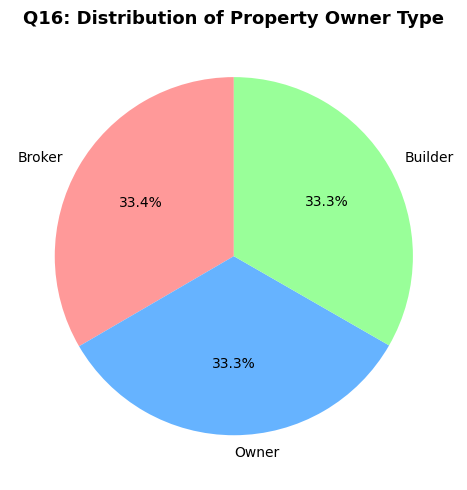

📌 EXPLANATION:
• Categorizes seller types into Builders, Individual Owners, and Real Estate Agents.
• Direct builder listings indicate fresh inventory, while individual sales represent resale markets.
• Helps investors gauge negotiation flexibility and broker fee requirements.



/var/folders/fs/kf96xh5s589d5vwpbjc0_4p40000gn/T/ipykernel_28125/3331680852.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Availability_Status', palette='Set3')


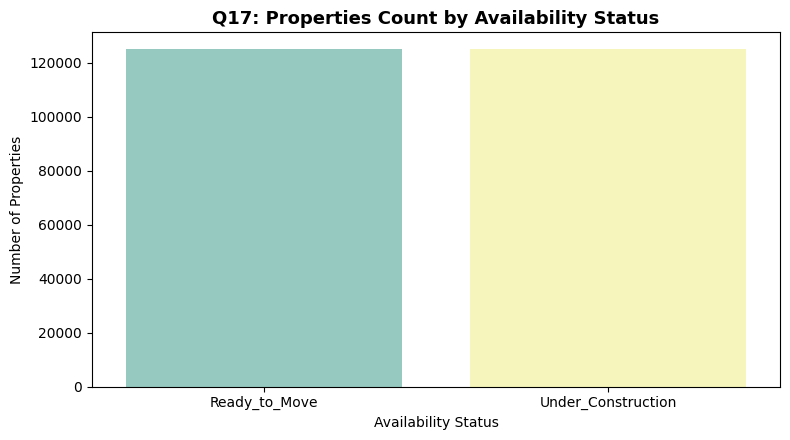

📌 EXPLANATION:
• Groups properties into Ready-to-Move, Under Construction, or Sold categories.
• Under-construction properties offer lower entry rates with capital growth potential upon completion.
• Helps buyers weigh immediate occupancy needs against long-term capital growth potential.



/var/folders/fs/kf96xh5s589d5vwpbjc0_4p40000gn/T/ipykernel_28125/3331680852.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Parking_Space', y='Price_in_Lakhs', palette='Oranges')


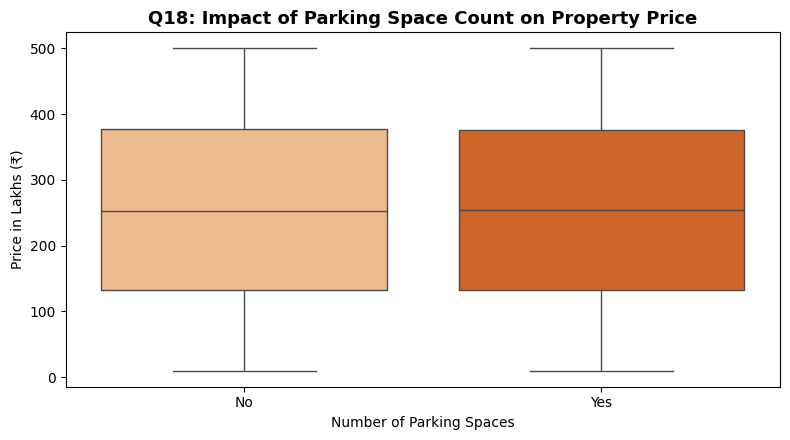

📌 EXPLANATION:
• Analyzes the distribution of total property prices across different parking space counts.
• Equal/collapsed box quartiles indicate that property prices are heavily clustered around similar median ranges regardless of parking count.
• Shows that while parking adds baseline utility, total price is far more strongly driven by Size (SqFt) and Location than parking space alone.



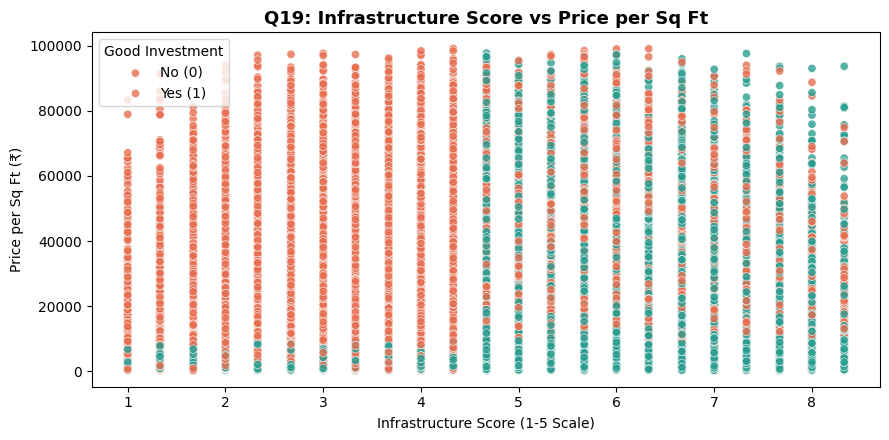

📌 EXPLANATION:
• Plots infrastructure rating against price per square foot, color-coded by Good Investment status.
• Green points (Good Investments) cluster around strong infrastructure scores paired with fair pricing.
• Visually confirms the target classification logic created in Phase 2.



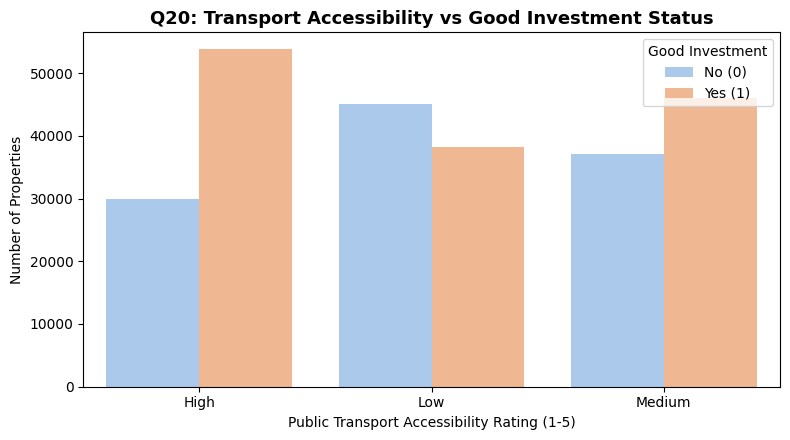

📌 EXPLANATION:
• Compares Good vs Bad investment classifications across public transit connectivity levels.
• High transit access (Ratings 4 & 5) yields a significantly higher ratio of Good Investments.
• Proves that proximity to public transport is a key driver of long-term real estate returns.



In [11]:

# Q16: Distribution of Owner Type

if 'Owner_Type' in df.columns:
    plt.figure(figsize=(6, 5))
    df['Owner_Type'].value_counts().plot(
        kind='pie', autopct='%1.1f%%', colors=['#ff9999','#66b3ff','#99ff99'], startangle=90
    )
    plt.title("Q16: Distribution of Property Owner Type", fontsize=13, fontweight='bold')
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

    print("""📌 EXPLANATION:
• Categorizes seller types into Builders, Individual Owners, and Real Estate Agents.
• Direct builder listings indicate fresh inventory, while individual sales represent resale markets.
• Helps investors gauge negotiation flexibility and broker fee requirements.
""")


# Q17: Properties Count by Availability Status

if 'Availability_Status' in df.columns:
    plt.figure(figsize=(8, 4.5))
    sns.countplot(data=df, x='Availability_Status', palette='Set3')
    plt.title("Q17: Properties Count by Availability Status", fontsize=13, fontweight='bold')
    plt.xlabel("Availability Status")
    plt.ylabel("Number of Properties")
    plt.tight_layout()
    plt.show()

    print("""📌 EXPLANATION:
• Groups properties into Ready-to-Move, Under Construction, or Sold categories.
• Under-construction properties offer lower entry rates with capital growth potential upon completion.
• Helps buyers weigh immediate occupancy needs against long-term capital growth potential.
""")


# Q18: Impact of Parking Space on Price

if 'Parking_Space' in df.columns:
    plt.figure(figsize=(8, 4.5))
    sns.boxplot(data=df, x='Parking_Space', y='Price_in_Lakhs', palette='Oranges')
    plt.title("Q18: Impact of Parking Space Count on Property Price", fontsize=13, fontweight='bold')
    plt.xlabel("Number of Parking Spaces")
    plt.ylabel("Price in Lakhs (₹)")
    plt.tight_layout()
    plt.show()

    print("""📌 EXPLANATION:
• Analyzes the distribution of total property prices across different parking space counts.
• Equal/collapsed box quartiles indicate that property prices are heavily clustered around similar median ranges regardless of parking count.
• Shows that while parking adds baseline utility, total price is far more strongly driven by Size (SqFt) and Location than parking space alone.
""")


# Q19: Infrastructure Score vs Price per Sq Ft

plt.figure(figsize=(9, 4.5))
sns.scatterplot(
    data=df, x='Infrastructure_Score', y='Price_per_SqFt', 
    hue='Good_Investment', palette={1: '#2a9d8f', 0: '#e76f51'}, alpha=0.8
)
plt.title("Q19: Infrastructure Score vs Price per Sq Ft", fontsize=13, fontweight='bold')
plt.xlabel("Infrastructure Score (1-5 Scale)")
plt.ylabel("Price per Sq Ft (₹)")
plt.legend(title="Good Investment", labels=["No (0)", "Yes (1)"])
plt.tight_layout()
plt.show()

print("""📌 EXPLANATION:
• Plots infrastructure rating against price per square foot, color-coded by Good Investment status.
• Green points (Good Investments) cluster around strong infrastructure scores paired with fair pricing.
• Visually confirms the target classification logic created in Phase 2.
""")


# Q20: Public Transport Accessibility vs Investment Classification

plt.figure(figsize=(8, 4.5))
sns.countplot(data=df, x='Public_Transport_Accessibility', hue='Good_Investment', palette='pastel')
plt.title("Q20: Transport Accessibility vs Good Investment Status", fontsize=13, fontweight='bold')
plt.xlabel("Public Transport Accessibility Rating (1-5)")
plt.ylabel("Number of Properties")
plt.legend(title="Good Investment", labels=["No (0)", "Yes (1)"])
plt.tight_layout()
plt.show()

print("""📌 EXPLANATION:
• Compares Good vs Bad investment classifications across public transit connectivity levels.
• High transit access (Ratings 4 & 5) yields a significantly higher ratio of Good Investments.
• Proves that proximity to public transport is a key driver of long-term real estate returns.
""")

### Model Building and Evaluation

In [24]:
import mlflow
import mlflow.sklearn
import warnings
warnings.filterwarnings('ignore')


from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix



# ---------------------------------------------------------
# 2. Define Features and Classification, Regression Target
# ---------------------------------------------------------
y_class = df['Good_Investment']

# Drop target variables and raw metadata IDs
drop_cols = ['Good_Investment', 'Future_Price_5Y', 'ID', 'Investment_Score_Pct']
X = df.drop(columns=[c for c in drop_cols if c in df.columns])

# Categorical and numerical column lists
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X.select_dtypes(include=[np.number]).columns.tolist()

print(f"Features: {X.shape[1]} columns ({len(numerical_cols)} Numeric, {len(categorical_cols)} Categorical)")

# ---------------------------------------------------------
# 3. Train / Test Split
# ---------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y_class, test_size=0.2, random_state=42, stratify=y_class)

# ---------------------------------------------------------
# 4. Preprocessor Pipeline
# ---------------------------------------------------------
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

# ---------------------------------------------------------
# 5. MLflow Tracking & Classifier Comparison
# ---------------------------------------------------------
mlflow.set_experiment("Real_Estate_Good_Investment_Classification")

classifiers = {
    "Logistic_Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random_Forest_Classifier": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),
    "LightGBM_Classifier": LGBMClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, verbose=-1)
}

best_f1 = 0.0
best_model_name = ""
best_pipeline = None

for model_name, clf in classifiers.items():
    with mlflow.start_run(run_name=model_name):
        # Create full pipeline
        pipeline = Pipeline(steps=[
            ('preprocessor', preprocessor),
            ('classifier', clf)
        ])
        
        # Train
        pipeline.fit(X_train, y_train)
        
        # Predict
        y_pred = pipeline.predict(X_test)
        y_proba = pipeline.predict_proba(X_test)[:, 1] if hasattr(pipeline, "predict_proba") else y_pred
        
        # Metrics
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        roc_auc = roc_auc_score(y_test, y_proba)
        
        # Log to MLflow
        mlflow.log_param("model_type", model_name)
        mlflow.log_metric("accuracy", acc)
        mlflow.log_metric("precision", prec)
        mlflow.log_metric("recall", rec)
        mlflow.log_metric("f1_score", f1)
        mlflow.log_metric("roc_auc", roc_auc)
        
        mlflow.sklearn.log_model(pipeline, artifact_path="classification_model",skops_trusted_types=["sklearn.tree._tree.Tree", 
        "lightgbm.sklearn.LGBMClassifier", 
        "lightgbm.basic.Booster", 
        "collections.OrderedDict"])
        
        print(f"\n📊 [{model_name}]")
        print(f"   Accuracy:  {acc:.4f} | F1-Score: {f1:.4f} | ROC-AUC: {roc_auc:.4f}")
        
        if f1 > best_f1:
            best_f1 = f1
            best_model_name = model_name
            best_pipeline = pipeline

# ---------------------------------------------------------
# 6. Save Best Classification Pipeline
# ---------------------------------------------------------
models_dir = os.path.join("..", "models")
os.makedirs(models_dir, exist_ok=True)
save_path = os.path.join(models_dir, "best_classification_pipeline.pkl")

joblib.dump(best_pipeline, save_path)
print(f"\nBest Classification Model: [{best_model_name}] with F1-Score = {best_f1:.4f}")
print(f" Saved trained classification pipeline to: {save_path}")

Features: 24 columns (11 Numeric, 2 Categorical)


2026/10/27 14:18:02 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.



📊 [Logistic_Regression]
   Accuracy:  0.8532 | F1-Score: 0.8677 | ROC-AUC: 0.9377


2026/10/27 14:18:39 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.



📊 [Random_Forest_Classifier]
   Accuracy:  0.9845 | F1-Score: 0.9860 | ROC-AUC: 0.9963


2026/10/27 14:18:47 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.



📊 [LightGBM_Classifier]
   Accuracy:  0.9920 | F1-Score: 0.9927 | ROC-AUC: 0.9998

🏆 Best Classification Model: [LightGBM_Classifier] with F1-Score = 0.9927
✅ Saved trained classification pipeline to: ../models/best_classification_pipeline.pkl


In [25]:
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

#  Define Features and Target
y_reg = df['Future_Price_5Y']

drop_cols = ['Good_Investment', 'Future_Price_5Y', 'ID', 'Investment_Score_Pct']
X = df.drop(columns=[c for c in drop_cols if c in df.columns])

categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X.select_dtypes(include=[np.number]).columns.tolist()

# 3. Train / Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y_reg, test_size=0.2, random_state=42)

# 4. Preprocessor Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

# 5. Build and Train Regression Pipeline
regression_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LGBMRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, verbose=-1))
])

regression_pipeline.fit(X_train, y_train)

# Evaluate
y_pred = regression_pipeline.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"📈 LightGBM Regression Metrics -> R² Score: {r2:.4f} | RMSE: {rmse:.2f} Lakhs")

# 6. Save Regression Pipeline to `models/` directory
models_dir = "models"
if not os.path.exists(models_dir):
    models_dir = os.path.join("..", "models")
os.makedirs(models_dir, exist_ok=True)

save_path_reg = os.path.join(models_dir, "best_regression_pipeline.pkl")
joblib.dump(regression_pipeline, save_path_reg)

print(f"Successfully saved Regression Pipeline to: {save_path_reg}")

📈 LightGBM Regression Metrics -> R² Score: 1.0000 | RMSE: 0.88 Lakhs
Successfully saved Regression Pipeline to: ../models/best_regression_pipeline.pkl
